# 5장 행동과 환경에 대한 작용 (실습)

능동 추론에서 행동이 어떻게 정해지는지 Hydar 로 확인한다.

1. 전방 모델: 일반화 좌표에서 감각의 각 차수가 행동에 얼마나 민감한가(∂ỹ/∂u)를 해석식과 수치 미분으로 맞춰 본다
2. 행동의 경사 하강: 「나는 깊이 4 로 내려가고 있다」는 편향된 생성 모델만으로 Hydar 가 목표 깊이에 가는가
3. 전방 모델을 부호 하나로 줄여도 되는가
4. 운영 명세의 강건함: 근육이 지치거나 해류가 밀어도 같은 믿음이 목표로 데려가는가. 같은 근육 명령을 그대로 재생하면 어떻게 되는가
5. 정밀도의 균형: 사전 정밀도와 감각 정밀도가 행동의 크기를 어떻게 바꾸는가

마지막으로 전방 모델의 부호가 틀렸을 때와 행동 학습률이 너무 클 때 무엇이 무너지는지 본다.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import koreanize_matplotlib  # 한글 글꼴과 마이너스 기호 설정

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.figsize": (6.4, 3.2), "figure.dpi": 200,
                     "axes.spines.top": False, "axes.spines.right": False})
print("준비 완료, numpy", np.__version__)

준비 완료, numpy 2.5.4


## 1. 전방 모델 ∂ỹ/∂u

생성 과정을 x′ = f(x, u) = a x + b u + v 로 두고(u, v 는 상수), 감각 사상은 비선형 g(x) = 25 e^(−0.1x) 로 둔다. 연쇄 법칙으로 감각의 시간 도함수를 풀면 다음과 같다.

- y = g(x) → ∂y/∂u = 0
- y′ = g′ f → ∂y′/∂u = b g′
- y″ = g″ f² + g′ a f → ∂y″/∂u = 2b f g″ + a b g′

x(t) 의 닫힌 해를 써서 감각 궤적을 만들고, 시간 미분과 u 에 대한 미분을 모두 수치로 구해 해석식과 비교한다.

In [2]:
a, b, v, x0 = -0.5, 1.0, 0.2, 2.0
g   = lambda x: 25 * np.exp(-0.1 * x)
g1  = lambda x: -2.5 * np.exp(-0.1 * x)
g2  = lambda x: 0.25 * np.exp(-0.1 * x)

def y_of_t(t, u):
    c = b * u + v
    return g((x0 + c / a) * np.exp(a * t) - c / a)     # x′ = a x + c 의 닫힌 해

def sensory_orders(u, h=1e-3):
    """t = 0 에서 y, y′, y″ 를 중심 차분으로 구한다."""
    ym, y0, yp = y_of_t(-h, u), y_of_t(0.0, u), y_of_t(h, u)
    return np.array([y0, (yp - ym) / (2 * h), (yp - 2 * y0 + ym) / h**2])

u0, du = 0.5, 1e-4
numeric = (sensory_orders(u0 + du) - sensory_orders(u0 - du)) / (2 * du)
f0 = a * x0 + b * u0 + v
analytic = np.array([0.0, b * g1(x0), 2 * b * f0 * g2(x0) + a * b * g1(x0)])
for k, name in enumerate(["y ", "y′", "y″"]):
    print(f"∂{name}/∂u   수치 {numeric[k]:+.5f}   해석식 {analytic[k]:+.5f}")

∂y /∂u   수치 +0.00000   해석식 +0.00000
∂y′/∂u   수치 -2.04683   해석식 -2.04683
∂y″/∂u   수치 +0.90061   해석식 +0.90060


## 2. 행동의 경사 하강 — 편향된 생성 모델

생성 과정: 깊이 x 의 속도는 추진력이 정한다(x′ = b u + d, 보통 b = 1, d = 0). 수온은 g(x) = 25 − 2x 이고, Hydar 는 수온 y 와 그 변화율 y′ 를 느낀다.

생성 모델: 믿음은 위치와 속도 μ̃ = [μ, μ′] 이고, 운동 방정식은 f(μ) = −(μ − v), 곧 「나는 v = 4 로 다가가고 있다」다. 행동 u 는 모델에 없다.

- 지각: μ̇ = μ′ − α ∂F/∂μ,   μ̇′ = −α ∂F/∂μ′
- 행동: u̇ = −α_u (∂ỹ/∂u)^T Π_z ε̃_y. 여기서 y 는 u 에 곧바로 반응하지 않고 y′ = g′ u 만 반응하므로 u̇ = −α_u g′ Π_z1 ε_y1 이다.

In [3]:
dt, T = 0.005, 20.0
g_T, dg_T = (lambda x: 25 - 2 * x), -2.0

def hydar(b=1.0, d=0.0, v=4.0, s2_w=1.0, s2_z0=0.1, s2_z1=0.1,
          a_mu=1.0, a_u=1.0, dy_du=None, seed=9, T=T):
    """행동하는 Hydar. dy_du 가 None 이면 정확한 전방 모델 g′ 를, 숫자면 그 상수를 쓴다."""
    rng = np.random.default_rng(seed)
    x = mu = mu1 = u = 0.0
    log = np.zeros((int(T / dt), 4))
    for i in range(log.shape[0]):
        xdot = b * u + d                                      # 생성 과정
        y0 = g_T(x) + 0.05 * rng.standard_normal()            # 수온
        y1 = dg_T * xdot + 0.05 * rng.standard_normal()       # 수온 변화율
        e0, e1 = y0 - g_T(mu), y1 - dg_T * mu1                # 감각 예측 오차
        ex = mu1 + (mu - v)                                   # 운동 방정식 오차 μ′ − f(μ)
        dF_dmu  = -dg_T * e0 / s2_z0 + ex / s2_w
        dF_dmu1 = -dg_T * e1 / s2_z1 + ex / s2_w
        mu  += dt * (mu1 - a_mu * dF_dmu)                     # 지각 (Dμ̃ 항 포함)
        mu1 += dt * (-a_mu * dF_dmu1)
        fwd = dg_T if dy_du is None else dy_du                # 전방 모델 ∂y′/∂u
        u   -= dt * a_u * fwd * e1 / s2_z1                    # 행동
        x   += dt * xdot
        log[i] = (i * dt, x, mu, u)
    return log

def at(log, sec):
    return log[min(int(round(sec / dt)), len(log) - 1)]

base = hydar()
print(" 시간    깊이 x   믿음 μ   행동 u")
for sec in [0, 1, 2, 4, 8, 20]:
    _, x, mu, u = at(base, sec)
    print(f"{sec:4.0f}s   {x:6.2f}   {mu:6.2f}   {u:6.2f}")
lead = base[: int(2 / dt), 2] - base[: int(2 / dt), 1]
print(f"처음 2초 동안 믿음이 실제보다 앞선 정도: 평균 {lead.mean():+.3f}, 최대 {lead.max():+.3f}")

 시간    깊이 x   믿음 μ   행동 u
   0s     0.00     0.02     0.00
   1s     0.79     0.83     1.41
   2s     2.47     2.47     1.76
   4s     5.05     5.01     0.58
   8s     3.89     3.92    -0.39
  20s     3.97     3.97     0.01
처음 2초 동안 믿음이 실제보다 앞선 정도: 평균 +0.045, 최대 +0.108


## 3. 전방 모델을 부호 하나로

정확한 ∂y′/∂u = g′ = −2 대신 부호만 맞춘 −1 을 쓴다. 크기 차이는 학습률이 흡수한다.

In [4]:
for label, fwd in [("정확한 전방 모델 −2", None), ("부호만 맞춘 −1", -1.0)]:
    L = hydar(dy_du=fwd)
    t90 = L[np.argmax(L[:, 1] > 3.6), 0]
    print(f"{label}:  깊이 3.6 도달 {t90:5.2f}s   20초 뒤 깊이 {L[-1, 1]:.3f}")

정확한 전방 모델 −2:  깊이 3.6 도달  2.68s   20초 뒤 깊이 3.966
부호만 맞춘 −1:  깊이 3.6 도달  3.12s   20초 뒤 깊이 4.070


## 4. 운영 명세의 강건함

Hydar 의 믿음은 「깊이 4 에 있다」는 결과만 말하고, 어떤 근육 명령을 낼지는 말하지 않는다. 생성 과정을 바꿔 본다.

- 근육이 지쳤다: b = 0.5
- 근육이 세졌다: b = 2
- 위로 미는 해류: d = −0.3

비교 대상으로, 정상 조건에서 기록한 행동 u(t) 를 같은 시각에 그대로 재생하는 개방 루프 제어를 둔다.

In [5]:
def replay(us, b=1.0, d=0.0):
    x, out = 0.0, np.zeros(len(us))
    for i, uu in enumerate(us):
        out[i] = x
        x += dt * (b * uu + d)
    return out

conds = [("정상", 1.0, 0.0), ("지친 근육 b=0.5", 0.5, 0.0),
         ("센 근육 b=2", 2.0, 0.0), ("위로 미는 해류 0.3", 1.0, -0.3)]
runs = {}
print("조건               능동 추론         명령 재생")
for name, b, d in conds:
    L = hydar(b=b, d=d)
    ol = replay(base[:, 3], b, d)
    runs[name] = (L, ol)
    print(f"{name:14s}     {L[-1, 1]:8.3f}       {ol[-1]:8.3f}")

조건               능동 추론         명령 재생
정상                    3.966          3.966
지친 근육 b=0.5           4.070          1.983
센 근육 b=2              4.004          7.932
위로 미는 해류 0.3          3.965         -2.032


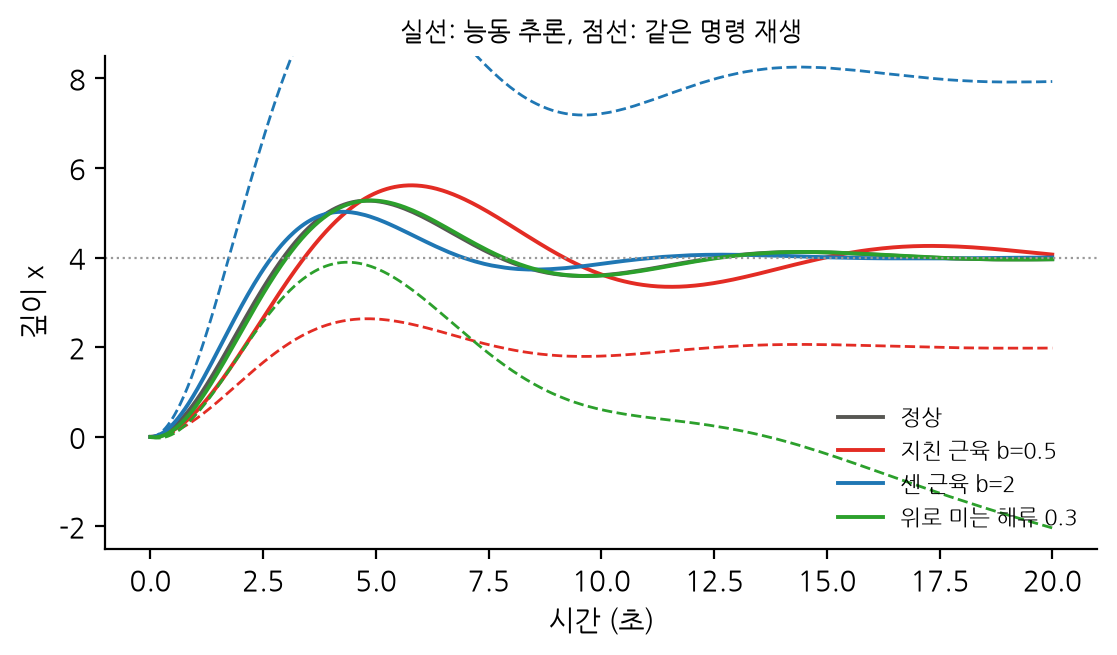

In [6]:
tt = base[:, 0]
colors = ["#575753", "#E32C24", "#1f77b4", "#2ca02c"]
for (name, (L, ol)), c in zip(runs.items(), colors):
    plt.plot(tt, L[:, 1], color=c, lw=1.4, label=name)
    if name != "정상":
        plt.plot(tt, ol, "--", color=c, lw=1.0)
plt.axhline(4, color="#999999", lw=0.8, ls=":")
plt.ylim(-2.5, 8.5)
plt.xlabel("시간 (초)")
plt.ylabel("깊이 x")
plt.legend(frameon=False, fontsize=8, loc="lower right")
plt.title("실선: 능동 추론, 점선: 같은 명령 재생", fontsize=9)
plt.show()

## 5. 정밀도의 균형

사전 정밀도(운동 방정식 오차의 정밀도 1/σ_w²)와 감각 정밀도(1/σ_z1²)를 따로 바꾼다.

In [7]:
def t_reach(L, level=3.6):
    hit = L[:, 1] > level
    return L[np.argmax(hit), 0] if hit.any() else np.inf

print("사전 분산 σ_w²   깊이 3.6 도달   4초 뒤 깊이   20초 뒤 깊이")
for s2w in [0.1, 1.0, 10.0, 100.0]:
    L = hydar(s2_w=s2w)
    r = t_reach(L)
    reach = f"{r:7.2f}s" if np.isfinite(r) else " 도달 못함"
    print(f"{s2w:10.1f}      {reach}      {at(L, 4)[1]:7.2f}      {L[-1, 1]:7.2f}")

print()
print("감각 분산 σ_z1²  깊이 3.6 도달   20초 뒤 깊이   최대 |ε_y1| 근사")
for s2z in [0.05, 0.1, 0.4, 1.6]:
    L = hydar(s2_z1=s2z)
    du = np.abs(np.diff(L[:, 3])) / dt                        # |u̇| = α_u·2·|ε_y1|/σ_z1²
    print(f"{s2z:10.2f}      {t_reach(L):8.2f}s      {L[-1, 1]:7.3f}      {(du * s2z / 2).max():8.3f}")

사전 분산 σ_w²   깊이 3.6 도달   4초 뒤 깊이   20초 뒤 깊이
       0.1         1.91s         4.00         4.00
       1.0         2.68s         5.05         3.97
      10.0         7.05s         1.39         4.93
     100.0       도달 못함         0.16         3.27

감각 분산 σ_z1²  깊이 3.6 도달   20초 뒤 깊이   최대 |ε_y1| 근사
      0.05          2.67s        3.968         0.222
      0.10          2.68s        3.966         0.234
      0.40          2.71s        3.955         0.470
      1.60          2.85s        3.883         1.191


## 6. 실패 조건 둘

첫째, 전방 모델의 부호를 반대로(+1) 준다. 둘째, 행동 학습률 α_u 를 키운다. 이산 시간 갱신에서 행동 쪽 곡률은 α_u·g′²/σ_z1² 이므로, 4장의 한계에 따르면 dt·α_u·g′²/σ_z1² < 2, 곧 α_u < 10 이어야 한다.

In [8]:
with np.errstate(all="ignore"):
    L = hydar(dy_du=+2.0, T=4.0)
    print("부호가 틀린 전방 모델:", "  ".join(f"{s}s 깊이 {at(L, s)[1]:.3g}" for s in [1, 2, 3, 4]))
    print()
    print("α_u   dt·α_u·g′²/σ_z1²   20초 뒤 깊이")
    for a_u in [5, 9, 10, 12]:
        L = hydar(a_u=a_u)
        print(f"{a_u:3d}        {dt * a_u * 4 / 0.1:5.2f}          {L[-1, 1]:.4g}")

부호가 틀린 전방 모델: 1s 깊이 -134  2s 깊이 -6.46e+04  3s 깊이 -3.06e+07  4s 깊이 -1.41e+10

α_u   dt·α_u·g′²/σ_z1²   20초 뒤 깊이
  5         1.00          4.004
  9         1.80          3.965
 10         2.00          nan
 12         2.40          nan


## 결론

- 일반화 좌표에서 행동은 감각의 0차에는 곧바로 닿지 않고 1차 이상에만 닿는다. 해석식과 수치 미분이 맞는다.
- 「깊이 4 로 다가가고 있다」는 편향된 믿음 하나로 Hydar 는 목표 깊이에 간다. 그동안 믿음은 실제 깊이보다 조금 앞서 간다.
- 전방 모델은 부호만 맞아도 목표에 간다. 크기는 속도만 바꾼다.
- 결과를 명세한 믿음은 근육의 세기나 해류가 바뀌어도 목표로 데려가지만, 같은 근육 명령을 재생하면 엉뚱한 깊이에 닿는다.
- 사전 정밀도가 높을수록 행동이 빠르고, 낮으면 행동이 거의 나오지 않는다. 감각 정밀도를 낮추면 예측 오차가 커져서 상쇄되므로 효과가 작다.
- 전방 모델의 부호가 틀리면 Hydar 는 반대쪽으로 끝없이 간다. 행동 학습률이 이산 시간 한계를 넘으면 발산한다.